In [1]:
print("Hello, Teknik Fisika!")

Hello, Teknik Fisika!


In [5]:
mass = 2.0          # float (setara double di C)
count = 5           # int
name = "sensor-A"   # str
active = True       # bool

print(type(mass), type(count), type(name), type(active))
print(7 / 2, 7 // 2, 7 % 2, 2 ** 10)
print(2 ** 100)
print(0.1 + 0.2)

<class 'float'> <class 'int'> <class 'str'> <class 'bool'>
3.5 3 1 1024
1267650600228229401496703205376
0.30000000000000004


In [9]:
temperature = float(input("Temperature (C): "))

if temperature < 20:
    status = "DINGIN"
elif temperature <= 30:
    status = "NORMAL"
else:
    status = "PANAS"

print(f"T = {temperature:.1f} C -> {status}")

Temperature (C): 27.4
T = 27.4 C -> NORMAL


In [10]:
x0, v0, a = 2.0, 5.0, 3.0      # m, m/s, m/s^2

print(" t(s)    x(m)")
for t in range(0, 6):
    x = x0 + v0 * t + 0.5 * a * t**2
    print(f"{t:4d} {x:8.2f}")

# metode Babilonia dengan while
s, x, tol = 2.0, 1.0, 1e-12
iterations = 0
while True:
    x_new = 0.5 * (x + s / x)
    iterations += 1
    if abs(x_new - x) < tol or iterations >= 100:
        break
    x = x_new
print(f"sqrt(2) ~= {x_new:.15f} after {iterations} iterations")

 t(s)    x(m)
   0     2.00
   1     8.50
   2    18.00
   3    30.50
   4    46.00
   5    64.50
sqrt(2) ~= 1.414213562373095 after 6 iterations


In [11]:
def kinetic_energy(mass, velocity):
    """Energi kinetik (J) dari massa (kg) dan kecepatan (m/s)."""
    return 0.5 * mass * velocity**2

def momentum(mass, velocity):
    return mass * velocity

print(f"E = {kinetic_energy(2.0, 3.0):.3f} J")
print(f"p = {momentum(2.0, 3.0):.3f} kg m/s")

E = 9.000 J
p = 6.000 kg m/s


In [19]:
voltage = [2.4, 3.1, 2.8, 4.0]
voltage.append(3.5)

print("n     =", len(voltage))
print("first =", voltage[0], " last =", voltage[-1])
print(f"mean  = {sum(voltage) / len(voltage):.3f} V")
print("min   =", min(voltage), " max =", max(voltage))

for i, v in enumerate(voltage):
    print(f"V[{i}] = {v:.1f}")

n     = 5
first = 2.4  last = 3.5
mean  = 3.160 V
min   = 2.4  max = 4.0
V[0] = 2.4
V[1] = 3.1
V[2] = 2.8
V[3] = 4.0
V[4] = 3.5


In [22]:
time, voltage = [], []

with open("Data/voltage.dat", "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith("#"):
            continue
        parts = line.split()
        time.append(float(parts[0]))
        voltage.append(float(parts[1]))

print("samples:", len(time))
print(f"V(0) = {voltage[0]:.3f} V, V(end) = {voltage[-1]:.3f} V")
print(f"drop = {100 * (1 - voltage[-1] / voltage[0]):.1f} %")

samples: 5
V(0) = 5.000 V, V(end) = 3.900 V
drop = 22.0 %


In [24]:
import numpy as np

mass = np.array([1.0, 2.0, 3.0, 4.0])        # kg
velocity = np.array([2.0, 3.0, 1.5, 0.5])    # m/s

energy = 0.5 * mass * velocity**2             # tanpa loop
print("E       =", energy)
print("E_total =", energy.sum(), "J")

# perbandingan: list biasa memerlukan loop
energy_list = [0.5 * m * v**2 for m, v in zip([1.0, 2.0, 3.0, 4.0], [2.0, 3.0, 1.5, 0.5])]
print("list    =", energy_list)

E       = [2.    9.    3.375 0.5  ]
E_total = 14.875 J
list    = [2.0, 9.0, 3.375, 0.5]


In [26]:
import numpy as np

t = np.linspace(0.0, 2.0, 21)            # 21 titik, langkah 0.1 s
x = 2.0 + 5.0 * t + 0.5 * 3.0 * t**2     # x(t) = x0 + v0 t + a t^2 / 2

print("number of points:", t.size)
print("t[:4] =", t[:4])
print("x[-1] =", x[-1], "m")
print(f"mean = {x.mean():.3f}, std = {x.std():.3f}, max = {x.max():.3f}")

number of points: 21
t[:4] = [0.  0.1 0.2 0.3]
x[-1] = 18.0 m
mean = 9.050, std = 4.869, max = 18.000


In [31]:
import numpy as np

T = np.array([29.5, 30.2, 28.9, 31.1, 30.0, 19.4, 33.0])

high = T > 30.0
print("mask       :", high)
print("above 30 C :", T[high])
print("count      :", np.count_nonzero(high))
print(f"percentage : {100 * np.mean(high):.1f} %")

outside = (T < 20.0) | (T > 30.0)
print("outside 20-30 C:", T[outside])

mask       : [False  True False  True False False  True]
above 30 C : [30.2 31.1 33. ]
count      : 3
percentage : 42.9 %
outside 20-30 C: [30.2 31.1 19.4 33. ]


In [34]:
import numpy as np

volt = np.loadtxt("Data/voltage.dat")
print("voltage.dat shape:", volt.shape)

data = np.genfromtxt("Data/motion.csv", delimiter=",", names=True)
print("columns:", data.dtype.names)
t = data["time_s"]
x = data["position_m"]
print("samples:", t.size)

voltage.dat shape: (5, 2)
columns: ('time_s', 'position_m')
samples: 5


In [36]:
import numpy as np

data = np.genfromtxt("Data/motion.csv", delimiter=",", names=True)
t, x = data["time_s"], data["position_m"]

dt = np.diff(t)
if not np.all(dt > 0):
    raise ValueError("time must increase strictly")

v = np.diff(x) / dt
k = np.argmax(np.abs(v))
first = np.argmax(np.abs(v) > 3.0)

print("v =", np.round(v, 4))
print(f"mean interval velocity  = {v.mean():.4f} m/s")
print(f"global average velocity = {(x[-1] - x[0]) / (t[-1] - t[0]):.4f} m/s")
print(f"max |v| = {abs(v[k]):.4f} m/s in [{t[k]:.2f}, {t[k+1]:.2f}] s")
print(f"|v| > 3 m/s first in [{t[first]:.2f}, {t[first+1]:.2f}] s")

v = [2.4 6.6 7.2 8.8]
mean interval velocity  = 6.2500 m/s
global average velocity = 6.2500 m/s
max |v| = 8.8000 m/s in [1.50, 2.00] s
|v| > 3 m/s first in [0.50, 1.00] s


saved gerak-posisi.pdf


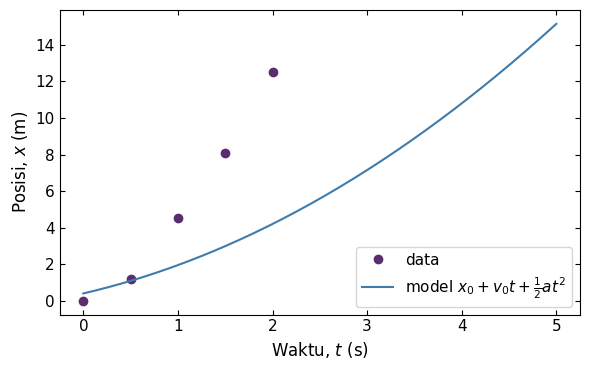

In [44]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("Data/motion.csv", delimiter=",", names=True)
t, x = data["time_s"], data["position_m"]

t_model = np.linspace(0.0, 5.0, 200)
x_model = 0.4 + 1.2 * t_model + 0.5 * 0.7 * t_model**2

fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.plot(t, x, "o", color="#5A2D6E", label="data")
ax.plot(t_model, x_model, "-", color="#3F7CAC",
        label=r"model $x_0 + v_0 t + \frac{1}{2} a t^2$")
ax.set_xlabel("Waktu, $t$ (s)", fontsize=12)
ax.set_ylabel("Posisi, $x$ (m)", fontsize=12)
ax.tick_params(direction="in", top=True, right=True, labelsize=11)
ax.legend(fontsize=11)
fig.tight_layout()
fig.savefig("gerak-posisi.pdf")
print("saved gerak-posisi.pdf")

samples          : 7
initial / final  : 85.00 C / 27.50 C
all rates < 0    : True
fastest cooling  : -4.760 C/min in [0, 5] min
slowest cooling  : -0.460 C/min in [25, 30] min


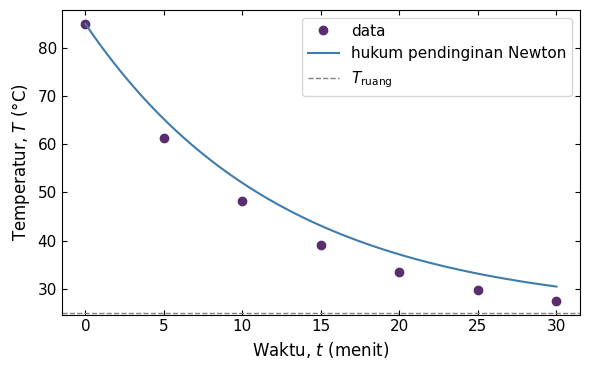

In [48]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("Data/cooling.csv", delimiter=",", names=True)
t, T = data["time_min"], data["temperature_C"]

rate = np.diff(T) / np.diff(t)          # C/min
i = np.argmin(rate)

print(f"samples          : {T.size}")
print(f"initial / final  : {T[0]:.2f} C / {T[-1]:.2f} C")
print(f"all rates < 0    : {np.all(rate < 0)}")
print(f"fastest cooling  : {rate[i]:.3f} C/min in [{t[i]:.0f}, {t[i+1]:.0f}] min")
print(f"slowest cooling  : {rate[-1]:.3f} C/min in [{t[-2]:.0f}, {t[-1]:.0f}] min")

T_room, k = 25.0, 0.08                  # parameter model
t_model = np.linspace(0, 30, 200)
T_model = T_room + (T[0] - T_room) * np.exp(-k * t_model)

fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.plot(t, T, "o", color="#5A2D6E", label="data")
ax.plot(t_model, T_model, "-", color="#3F7CAC", label="hukum pendinginan Newton")
ax.axhline(T_room, color="gray", linestyle="--", linewidth=1, label=r"$T_{\mathrm{ruang}}$")
ax.set_xlabel("Waktu, $t$ (menit)", fontsize=12)
ax.set_ylabel("Temperatur, $T$ (°C)", fontsize=12)
ax.tick_params(direction="in", top=True, right=True, labelsize=11)
ax.legend(fontsize=11)
fig.tight_layout()
fig.savefig("pendinginan.pdf")

samples   = 100, duration = 10.00 s
amplitude = 0.499937 m
RMS       = 0.351781 m
A/sqrt(2) = 0.353509 m
sign changes = 9


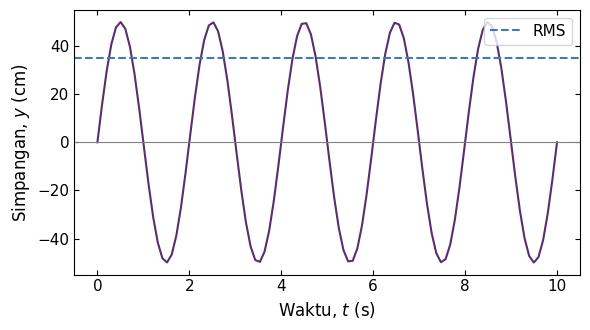

In [52]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("Data/wave.csv", delimiter=",", names=True)
t, y = data["time_s"], data["displacement_m"]

amplitude = np.max(np.abs(y))
rms = np.sqrt(np.mean(y**2))
signs = np.sign(y)
signs = signs[signs != 0]               # abaikan sampel yang tepat nol
crossings = np.count_nonzero(signs[:-1] * signs[1:] < 0)

print(f"samples   = {y.size}, duration = {t[-1] - t[0]:.2f} s")
print(f"amplitude = {amplitude:.6f} m")
print(f"RMS       = {rms:.6f} m")
print(f"A/sqrt(2) = {amplitude / np.sqrt(2):.6f} m")
print(f"sign changes = {crossings}")

fig, ax = plt.subplots(figsize=(6.0, 3.4))
ax.plot(t, 100 * y, "-", color="#5A2D6E", linewidth=1.5)
ax.axhline(0, color="gray", linewidth=0.8)
ax.axhline(100 * rms, color="#3F7CAC", linestyle="--", label="RMS")
ax.set_xlabel("Waktu, $t$ (s)", fontsize=12)
ax.set_ylabel("Simpangan, $y$ (cm)", fontsize=12)
ax.tick_params(direction="in", top=True, right=True, labelsize=11)
ax.legend(fontsize=11, loc="upper right")
fig.tight_layout()
fig.savefig("gelombang.pdf")